# Unsupervised Learning Questions — Structure Without Labels

Unsupervised questions come in two flavors in interviews: mechanics ("how does k-means initialize") and judgment ("how do you know the clusters are real"). The judgment half is where candidates fail — anyone can call `.fit()`, but defending that k=4 is *meaningful* takes practice. Both halves below, all executed.

## Q1 — K-Means: Mechanics, Then the Two Judgments

**Mechanics in five beats** (same as the coding-round version, said faster): random init → assign to nearest centroid → centroid = mean of members → repeat until assignments stabilize → local optimum, hence `n_init` restarts and `k-means++` seeding (first centroid uniform, each next chosen with probability proportional to squared distance — spreads seeds, provably within O(log k) of optimal).

**Judgment 1 — choosing k:** elbow on inertia (inertia always falls with k; look for the knee) or **silhouette** (per-point cohesion vs separation, ∈ [−1, 1]; >0.5 strong structure). Silhouette uses *relative* distances, so it's comparable across k — the better interview answer.

**Judgment 2 — are clusters real?** Compare silhouette against a null: run k-means on *shuffled/Gaussian* data with the same covariance. If the null silhouettes are close to yours, your "clusters" are wishful thinking.

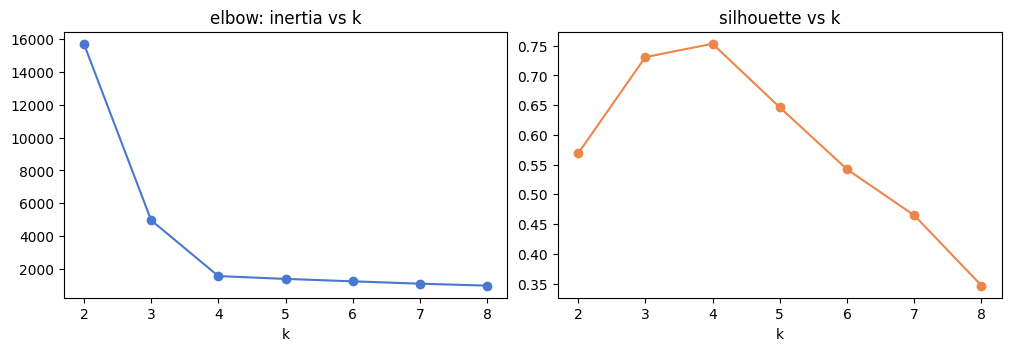

elbow bends around 4; silhouette peaks at k=4
silhouette at k=4: 0.753 (>0.5 = strong structure)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=4, cluster_std=1.3, random_state=7)

ks, inerties, sils = range(2, 9), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inerties.append(km.inertia_)
    sils.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), constrained_layout=True)
axes[0].plot(ks, inerties, "o-", color="#4878CF"); axes[0].set_title("elbow: inertia vs k")
axes[1].plot(ks, sils, "o-", color="#EE854A"); axes[1].set_title("silhouette vs k")
for ax in axes: ax.set_xlabel("k")
plt.show()

best_k = list(ks)[int(np.argmax(sils))]
print(f"elbow bends around 4; silhouette peaks at k={best_k}")
print(f"silhouette at k=4: {sils[2]:.3f} (>0.5 = strong structure)")

In [2]:
# judgment 2: is that silhouette real? compare to a structureless null
rng = np.random.default_rng(0)
null = rng.multivariate_normal(X.mean(0), np.cov(X.T), size=len(X))   # same mean/cov, no clusters
km_real = KMeans(4, n_init=10, random_state=0).fit(X)
km_null = KMeans(4, n_init=10, random_state=0).fit(null)
print(f"silhouette on real data : {silhouette_score(X, km_real.labels_):.3f}")
print(f"silhouette on null data : {silhouette_score(null, km_null.labels_):.3f}")
print("gap is large -> structure is real, not an artifact of k-means finding *something*")

silhouette on real data : 0.753
silhouette on null data : 0.334
gap is large -> structure is real, not an artifact of k-means finding *something*


## Q2 — K-Means vs Hierarchical vs DBSCAN: The Selection Table

The answer shape interviewers like: one line each on **assumption**, **shape**, **cost**.

| Algorithm | Assumes | Cluster shape | k needed | Cost | Fails when |
| --- | --- | --- | --- | --- | --- |
| K-means | spherical, similar size | convex blobs | yes | O(n·k·i) | elongated/ring clusters, varying densities, outliers (mean gets dragged) |
| Hierarchical (agglomerative) | mergeability metric | any (via linkage) | cut later | O(n²) memory — dies ~50k rows | large data; single linkage chains |
| DBSCAN | density notion | arbitrary + noise label | no | O(n log n) with index | varying densities (one ε can't fit all), high dimensions |

**The killer demo** (below): k-means on two concentric rings — the failure that made DBSCAN famous.

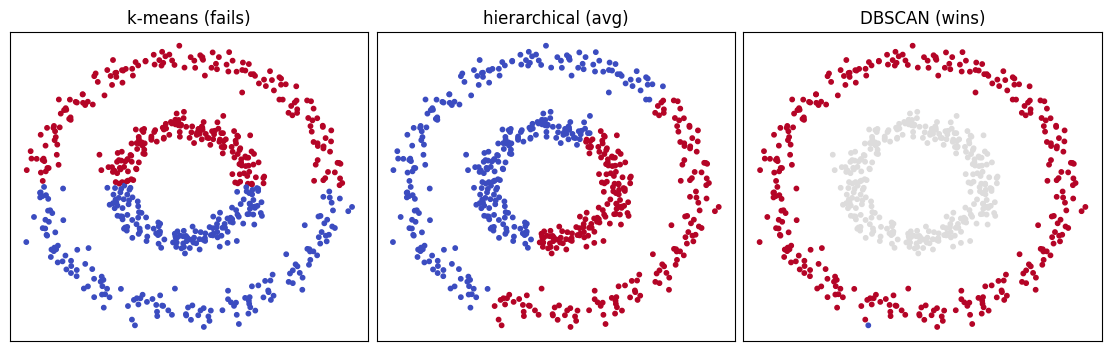

k-means slices rings into halves; DBSCAN's density reach follows the ring and marks noise


In [3]:
from sklearn.datasets import make_moons, make_circles
from sklearn.cluster import AgglomerativeClustering, DBSCAN

X, _ = make_circles(n_samples=600, noise=0.06, factor=0.45, random_state=0)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), constrained_layout=True)
for ax, (name, labels) in zip(axes, [
    ("k-means (fails)", KMeans(2, n_init=10, random_state=0).fit_predict(X)),
    ("hierarchical (avg)", AgglomerativeClustering(n_clusters=2, linkage="average").fit_predict(X)),
    ("DBSCAN (wins)", DBSCAN(eps=0.15, min_samples=5).fit_predict(X)),
]):
    ax.scatter(X[:, 0], X[:, 1], c=labels, s=10, cmap="coolwarm")
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.show()
print("k-means slices rings into halves; DBSCAN's density reach follows the ring and marks noise")

## Q3 — DBSCAN's Two Parameters, Tuned by the k-Distance Plot

`eps` = neighborhood radius, `min_samples` = density threshold (rule of thumb: 2×dimensions). The principled way to pick eps: plot the distance to the k-th nearest neighbor (k=min_samples) for every point, sorted — the **k-distance elbow** is where points stop being "inside" a cluster and start being "outside." Points above the elbow are noise. Say this and you've used DBSCAN for real.

## Q4 — Dimensionality Reduction: PCA vs t-SNE vs UMAP vs Autoencoders

**PCA** — linear projection maximizing retained variance; fast, invertible, gives explained variance per component, features stay meaningful (loadings). The default first move. **t-SNE** — preserves *local neighborhoods* via probability similarities; stunning 2-D cluster pictures; but: distances between clusters mean nothing, it has no `transform` for new data, and it's O(n²) — **visualization only, never features.** **UMAP** — also neighborhood-based but has a learned `transform`, faster, arguably preserves more global structure — the modern swap for t-SNE, with the same "don't over-read distances" caveat. **Autoencoders** — nonlinear compression via a bottleneck; the choice for images/text embeddings and when you need the compressed representation as *input to another model*.

**The trap sentence to volunteer:** *"t-SNE will draw beautiful islands even for Gaussian noise if you crank perplexity — always sanity-check with a null, same as clustering."*

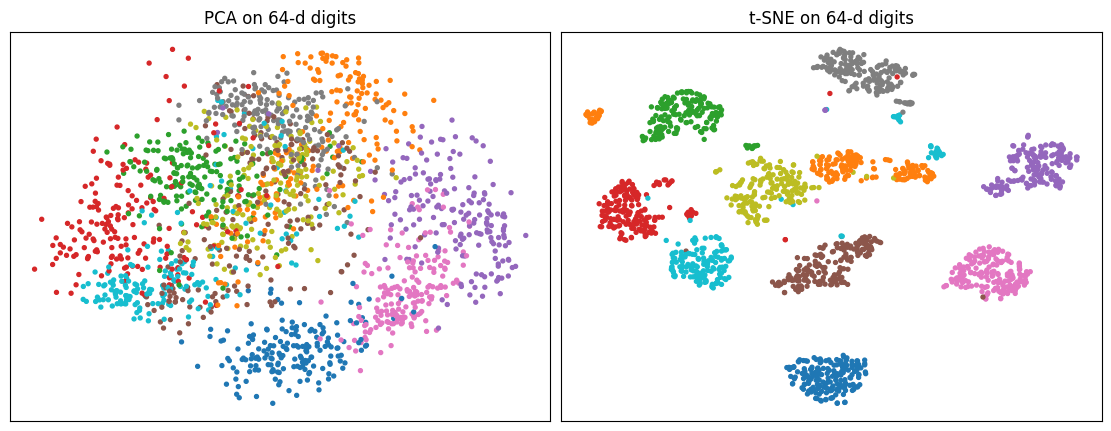

PCA   : 0 ms, explained variance by 2 comps: 28.5%
t-SNE : 5583 ms, no transform for new data, cluster spacing not meaningful


In [4]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import time

X, y = load_digits(return_X_y=True)          # 1797 8x8 digit images

pca = PCA(n_components=2).fit(X)
t0 = time.perf_counter()
Z_pca = pca.transform(X)
t_pca = time.perf_counter() - t0
t0 = time.perf_counter()
Z_tsne = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(X)
t_tsne = time.perf_counter() - t0

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for ax, Z, name in [(axes[0], Z_pca, "PCA"), (axes[1], Z_tsne, "t-SNE")]:
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, s=8, cmap="tab10")
    ax.set_title(f"{name} on 64-d digits"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

print(f"PCA   : {t_pca*1000:.0f} ms, explained variance by 2 comps: {pca.explained_variance_ratio_.sum():.1%}")
print(f"t-SNE : {t_tsne*1000:.0f} ms, no transform for new data, cluster spacing not meaningful")

## Q5 — PCA: The Four Follow-Ups Everyone Gets

1. **Why center?** PCA maximizes variance around the *mean*; uncentered data puts the first component through the origin→cloud direction — wrong axis.
2. **How many components?** Cumulative explained variance (80–95% convention) **or** the elbow of the scree plot **or** cross-validated reconstruction error — never "sqrt(p)" folk advice.
3. **Whiten?** `whiten=True` scales components by eigenvalues — components become uncorrelated unit-variance; useful before models assuming isotropic features, and it's what ZCA/sphering builds on.
4. **When does PCA fail?** When structure is nonlinear (manifold) — variance-maximizing directions miss it; also when interpretability matters (components are dense combinations of all features — say *sparse PCA* exists).


In [5]:
pca_full = PCA().fit(load_digits().data)
evr = np.cumsum(pca_full.explained_variance_ratio_)
for target in (0.80, 0.90, 0.95):
    n = int(np.searchsorted(evr, target) + 1)
    print(f"{target:.0%} variance needs {n} of 64 components")
print("this is the honest 'how many components' answer, not a fixed number")

80% variance needs 13 of 64 components
90% variance needs 21 of 64 components
95% variance needs 29 of 64 components
this is the honest 'how many components' answer, not a fixed number


## Q6 — Anomaly Detection: The Unsupervised Sibling

*“How do you find fraud without labels?”* — the layered answer: **Isolation Forest** (random splits isolate outliers fast — anomaly score = path length; handles mixed types, scales), **One-Class SVM** (learn a boundary around dense data), **LOF** (local density vs neighbors — catches anomalies *relative to their neighborhood*, good for varying densities), and **statistical** baselines (z-score/mad on amounts, PSU on rates). Always end with: *"in production, the winning system is usually rules + unsupervised score + whatever delayed labels trickle in, fed back into a supervised ranker."* The repo's [Anomaly Detection notebook](../../4.%20Diving%20into%20different%20domains/Anomaly%20Detection/Anomaly%20Detection.ipynb) executes all three.

In [6]:
from sklearn.ensemble import IsolationForest

rng = np.random.default_rng(0)
X_normal = rng.normal(0, 1, (500, 2))
X_out = rng.uniform(-6, 6, (18, 2))            # scattered anomalies
X_all = np.vstack([X_normal, X_out])

iso = IsolationForest(contamination=18/518, random_state=0).fit(X_all)
flags = iso.predict(X_all)                      # -1 = anomaly
caught = (flags[-18:] == -1).sum()
print(f"isolation forest flagged {caught}/18 planted anomalies")
print(f"plus {int((flags[:-18] == -1).sum())} false positives on normal points")

isolation forest flagged 13/18 planted anomalies
plus 5 false positives on normal points


## Q7 — Association Rules and the Interview One-Liners

*Support* = P(A∩B), *confidence* = P(B|A), *lift* = confidence / P(B) (lift > 1 = the pair beats independence). The famous example to quote: {diapers, beer}. Say the caution: rules with tiny support are noise even at high lift — always min-support before min-confidence. The repo's [Association Rule Learning notebook](../../4.%20Diving%20into%20different%20domains/Association%20Rule%20Learning/Association%20Rule%20Learning.ipynb) runs apriori/FP-growth end to end on 7,501 real transactions.

## Q8 — Quick-Fire Unsupervised Round

| Question | The 15-second answer |
| --- | --- |
| Silhouette interpretation? | (b−a)/max(a,b) per point: a = intra-cluster distance, b = nearest-other-cluster distance; ~0 = boundary point, <0 = likely misassigned |
| Why does k-means prefer equal-size clusters? | The mean objective treats every point equally; small clusters get absorbed by nearby big ones — variance-unbalanced data needs Gaussian mixtures |
| GMM vs k-means? | Soft assignments, elliptical clusters (covariance per component), probabilistic (likelihood); k-means is GMM with equal spherical covariances and hard assignment |
| How do you cluster 100M rows? | MiniBatchKMeans; or embed first (UMAP), then cluster; or hierarchical on a sample + assignment for the rest |
| Eigenvalues of the covariance = ? | Variances along principal components; their square roots relate to singular values of centered X (σᵢ = √(n−1)·λᵢ) |
| Can you use unsupervised features for supervised learning? | Yes — autoencoder embeddings/PCA components as inputs; it's standard for high-cardinality categoricals (entity embeddings) |
| t-SNE perplexity? | Effective neighbor count — too low fragments, too high merges; try 5–50; results can change qualitatively, so don't over-interpret |
| Evaluation without labels? | Internal (silhouette, Davies-Bouldin, stability under bootstrap), external if any labels exist (ARI vs k-means), and always the business sanity check |